# Peak annotation enrichment

`epione.tl.peak_anno_enrichment` ports ArchR's **`peakAnnoEnrichment`**: for each
cell group, the marker peaks passing a cutoff (e.g. `FDR <= 0.1 & Log2FC >= 0.5`)
are tested for over-representation of a peak annotation (TF motifs, ENCODE ChIP-seq
peaks, custom region sets, …) with a hypergeometric test.

| ArchR | Epione |
|---|---|
| `addMotifAnnotations` | `epi.tl.add_motif_matrix` (existing) |
| `addPeakAnnotations` | `epi.tl.add_peak_annotations` |
| `addArchRAnnotations` | `epi.tl.add_archr_annotations` |
| `peakAnnoEnrichment` | `epi.tl.peak_anno_enrichment` |
| `customEnrichment` | `epi.tl.custom_enrichment` |
| `plotEnrichHeatmap` / `enrichHeatmap` | `epi.pl.enrich_heatmap` |

The port is numerically exact: given the same marker statistics, every output matches
ArchR 1.0.3 to ≤ 1e-12 on ArchR's Hematopoiesis project (see the last section).

For marker group $g$ and annotation $a$, with $N$ background peaks, $K$ of them
annotated, $n$ foreground (marker) peaks and $k$ of them annotated:

$$\mathrm{mlog10p} = -\log_{10} P(X \ge k),\quad X \sim \mathrm{Hypergeom}(N, K, n),
\qquad \mathrm{Enrichment} = \frac{k/n}{K/N}.$$

ArchR rounds `mlog10p` to 4 decimals and reports `mlog10Padj = max(mlog10p − log10(9), 0)`.
Epione reproduces both choices exactly.


## Data

This tutorial runs on the ArchR Hematopoiesis dataset (BMMC, CD34⁺ BMMC and PBMC; hg19)
built **with Epione only** in [`t_archr_heme_data`](t_archr_heme_data): fragments from
`epi.datasets.archr_hematopoiesis`, QC, iterative LSI, Leiden clusters, UMAP, MACS3
peaks, a JASPAR 2020 motif matrix (`epi.tl.add_motif_matrix`) and chromVAR background
peaks (`epi.tl.add_background_peaks`). Run that notebook once and point
`EPIONE_ARCHR_HEME` at its output directory.

In [1]:
%matplotlib inline
import os, pathlib
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt
from IPython.display import display

import epione as epi

DATA = pathlib.Path(os.environ.get('EPIONE_ARCHR_HEME', 'data_archr_heme'))
ANNO_CACHE = DATA / 'annotations'

In [2]:
%%time
adata = ad.read_h5ad(DATA / 'heme_peaks.h5ad')
adata.obs['log10_nFrags'] = np.log10(adata.obs['n_fragment'].astype(float))
gs = ad.read_h5ad(DATA / 'heme_gene_scores.h5ad')
# the motif matrix (peaks x motifs) and background peaks live in varm, as written by
# epi.tl.add_motif_matrix / epi.tl.add_background_peaks
print(adata.shape, '| motif matrix', adata.varm['motif'].shape, '| bg peaks', adata.varm['bg_peaks'].shape)
print('motif names, e.g.', list(adata.uns['motif_names'][:3]))

(10705, 232272) | motif matrix (232272, 746) | bg peaks (232272, 50)
motif names, e.g. ['MA0004.1_Arnt', 'MA0006.1_Ahr::Arnt', 'MA0019.1_Ddit3::Cebpa']
CPU times: user 338 ms, sys: 335 ms, total: 673 ms
Wall time: 676 ms


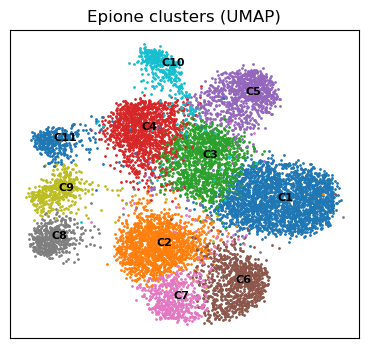

In [3]:
order = sorted(adata.obs.Clusters.unique(), key=lambda s: int(s[1:]))
fig, ax = plt.subplots(figsize=(4.5, 4))
for c in order:
    m = (adata.obs.Clusters == c).to_numpy()
    ax.scatter(*adata.obsm['X_umap'][m].T, s=1, label=c, rasterized=True)
    x, y = np.median(adata.obsm['X_umap'][m], axis=0); ax.text(x, y, c, fontsize=8, weight='bold')
ax.set_xticks([]); ax.set_yticks([]); ax.set_title('Epione clusters (UMAP)')
plt.show()

Cluster numbers come from Epione's own clustering, so we name the lineages from gene
scores instead of hard-coding IDs: the B-cell cluster has the highest mean `MS4A1`
score, the erythroid cluster the highest `GATA1`, and so on.

In [4]:
lin_markers = {'B': 'MS4A1', 'erythroid': 'GATA1', 'monocyte': 'CD14', 'T/NK': 'CD3D'}
gx = pd.DataFrame({g: np.asarray(gs[:, g].X.todense()).ravel() for g in lin_markers.values()},
                  index=gs.obs_names)
means = np.log2(gx + 1).groupby(gs.obs['Clusters'].values, observed=True).mean()
lineage = {lin: means[g].idxmax() for lin, g in lin_markers.items()}
display(means.round(2).loc[order].T)
lineage

,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11
MS4A1,0.05,0.02,0.06,0.04,0.04,0.03,0.00,0.59,0.24,0.10,0.13
GATA1,0.02,0.02,0.06,0.02,0.32,0.02,0.01,0.04,0.02,0.01,0.04
CD14,1.11,0.49,0.70,0.53,0.53,0.58,0.74,0.42,0.39,0.46,0.45
CD3D,0.08,0.59,0.10,0.11,0.09,0.62,0.62,0.10,0.08,0.18,0.10


{'B': 'C8', 'erythroid': 'C5', 'monocyte': 'C1', 'T/NK': 'C6'}

## Marker peaks

`epi.tl.find_marker_features` runs a Wilcoxon test of each cluster against a
background of cells matched on TSS enrichment and log10(fragments), mirroring ArchR's
`getMarkerFeatures(bias = c("TSSEnrichment", "log10(nFrags)"))`.

In [5]:
%%time
markers = epi.tl.find_marker_features(
    adata, group_by='Clusters', bias_vars=['tsse', 'log10_nFrags'], seed=1, verbose=False)
markers.head()

CPU times: user 4min 23s, sys: 49.5 s, total: 5min 13s
Wall time: 5min 13s


,group,feature,mean_fg,mean_bg,pct_fg,pct_bg,log2_fc,U,z,p_value,fdr,n_fg,n_bg
0,C1,chr1:115415-115915,0.000,0.001212,0.0000,0.000606,-10.244508,1649000.0,-1.100964,0.270912,0.425238,2000,1650
1,C1,chr1:540581-541081,0.003,0.003030,0.0015,0.001818,-0.014495,1649476.5,-0.235457,0.813854,0.905019,2000,1650
2,C1,chr1:565037-565537,0.004,0.002424,0.0020,0.001212,0.722232,1651300.0,0.584707,0.558745,0.689124,2000,1650
3,C1,chr1:569133-569633,0.006,0.010909,0.0030,0.005455,-0.862388,1645950.0,-1.153499,0.248706,0.418958,2000,1650
4,C1,chr1:713796-714296,0.126,0.125455,0.0740,0.075152,0.006259,1648210.5,-0.124068,0.901261,0.942422,2000,1650


## Motif enrichment in marker peaks

`markers` may be the long table above, a dict of ArchR-style assays
(peaks × groups: `FDR`, `Log2FC`, …) or an `adata.uns` key. The `cutoff` uses the same
syntax as ArchR (`&`, `|`, comparisons on assay names). The long table's
`fdr`/`log2_fc` columns are also exposed as `FDR`/`Log2FC`.

In [6]:
%%time
enrich = epi.tl.peak_anno_enrichment(
    markers, adata, annotation='motif',
    cutoff='FDR <= 0.1 & Log2FC >= 0.5', key_added='motif_enrichment', verbose=False)
list(enrich)

CPU times: user 12.8 s, sys: 682 ms, total: 13.5 s
Wall time: 13.5 s


['mlog10Padj',
 'mlog10p',
 'Enrichment',
 'BackgroundProporition',
 'nBackground',
 'BackgroundFrequency',
 'CompareProportion',
 'nCompare',
 'CompareFrequency',
 'feature']

In [7]:
# Number of marker peaks per cluster and the top motifs (cf. ArchR's per-cluster tables)
summary = pd.DataFrame({
    'n_marker_peaks': enrich['nCompare'].iloc[0].astype(int),
    'top motifs (mlog10Padj)': [
        ', '.join(f'{m} ({v:.0f})' for m, v in enrich['mlog10Padj'][g].nlargest(4).items())
        for g in enrich['mlog10Padj'].columns],
})
summary.loc[sorted(summary.index, key=lambda s: int(s[1:]))]

,n_marker_peaks,top motifs (mlog10Padj)
C1,30293,"MA0102.4_CEBPA (816), MA0836.2_CEBPD (739), MA..."
C2,7372,"MA0076.2_ELK4 (82), MA0523.1_TCF7L2 (80), MA15..."
C3,4477,"MA0836.2_CEBPD (178), MA0102.4_CEBPA (145), MA..."
C4,17858,"MA0764.2_ETV4 (181), MA0002.2_RUNX1 (180), MA0..."
C5,15057,"MA0140.2_GATA1::TAL1 (1721), MA0482.2_GATA4 (1..."
C6,12970,"MA1513.1_KLF15 (694), MA0506.1_NRF1 (508), MA0..."
C7,3023,"MA1513.1_KLF15 (810), MA1564.1_SP9 (629), MA07..."
C8,2085,"MA0081.2_SPIB (92), MA0080.5_SPI1 (78), MA0517..."
C9,1673,"MA0521.1_Tcf12 (141), MA1631.1_ASCL1(var.2) (1..."
C10,2782,"MA0521.1_Tcf12 (191), MA0816.1_Ascl2 (177), MA..."


In [8]:
# Full ArchR-style table for the B-cell cluster
g = lineage['B']
pd.DataFrame({a: enrich[a][g] for a in ['CompareFrequency', 'nCompare', 'BackgroundFrequency',
                                        'nBackground', 'Enrichment', 'mlog10p', 'mlog10Padj']}) \
  .sort_values('mlog10p', ascending=False).head(8)

,CompareFrequency,nCompare,BackgroundFrequency,nBackground,Enrichment,mlog10p,mlog10Padj
MA0081.2_SPIB,1070.0,2085.0,69385.0,232272.0,1.717944,92.9869,92.032657
MA0080.5_SPI1,1176.0,2085.0,83972.0,232272.0,1.560140,78.7856,77.831357
MA0517.1_STAT1::STAT2,849.0,2085.0,56593.0,232272.0,1.671228,60.6480,59.693757
MA0050.2_IRF1,1141.0,2085.0,87329.0,232272.0,1.455519,56.4425,55.488257
MA0598.3_EHF,749.0,2085.0,53629.0,232272.0,1.555869,39.6479,38.693657
MA1558.1_SNAI1,480.0,2085.0,29505.0,232272.0,1.812326,38.0601,37.105857
MA1115.1_POU5F1,398.0,2085.0,22610.0,232272.0,1.960981,38.0475,37.093257
MA0627.2_POU2F3,406.0,2085.0,24226.0,232272.0,1.866960,34.2140,33.259757


### Enrichment heatmap

`epi.pl.enrich_heatmap` reproduces `plotEnrichHeatmap`: the top `n` annotations per
group above `cutoff`, clipped at `p_max`, row-scaled to 0-100, rows ordered by ArchR's
binary sort, and columns ordered by complete-linkage clustering (R's `hclust`). Row labels carry the row maximum,
as in ArchR. The ArchR tutorial uses `n = 7, transpose = TRUE`.

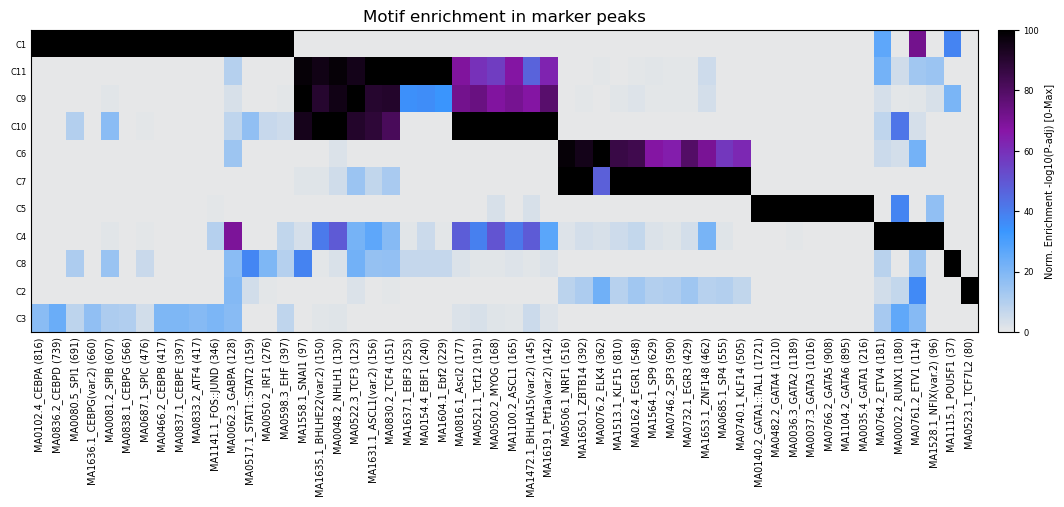

In [9]:
fig, ax = epi.pl.enrich_heatmap(enrich, n=7, transpose=True, figsize=(13, 4), show=False)
ax.set_title('Motif enrichment in marker peaks')
plt.show()

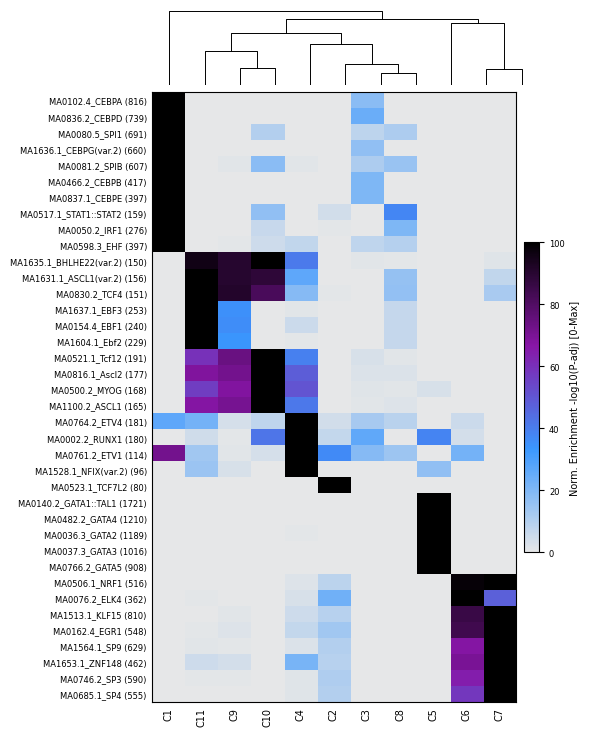

In [10]:
fig, ax = epi.pl.enrich_heatmap(enrich, n=5, figsize=(5, 9), show=False)
plt.show()

### Matched background peaks

With `background='bgdPeaks'` the background is the marker peaks plus their
GC/accessibility-matched background peaks (`adata.varm['bg_peaks']`, from
`epi.tl.add_background_peaks`). This controls for the GC bias of marker peaks.

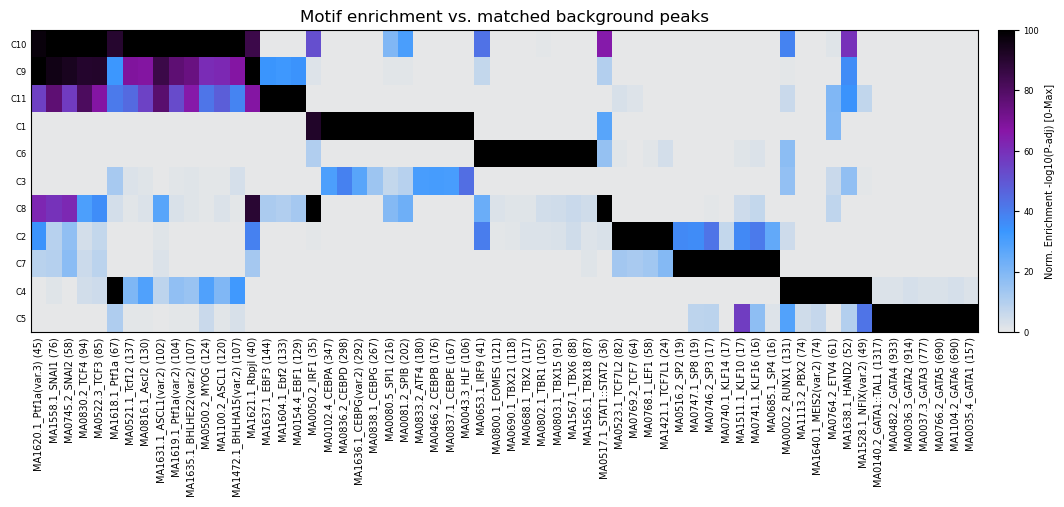

In [11]:
enrich_bgd = epi.tl.peak_anno_enrichment(markers, adata, annotation='motif',
                                         background='bgdPeaks', verbose=False)
fig, ax = epi.pl.enrich_heatmap(enrich_bgd, n=7, cutoff=2, transpose=True, figsize=(13, 4), show=False)
ax.set_title('Motif enrichment vs. matched background peaks'); plt.show()

## Custom region sets — `add_peak_annotations`

Any collection of genomic regions (BED files or DataFrames) can be turned into a binary
peak × region-set matrix (`addPeakAnnotations`). Here: promoters (TSS ± 1 kb), the 10 %
most GC-rich peaks, and distal peaks (> 3 kb from any TSS), all derived from the gene
annotation and the peak set.

In [12]:
genes = gs.var
tss_pos = np.where(genes['strand'].values == '-', genes['end'].values, genes['start'].values)
tss = pd.DataFrame({'chrom': genes['chrom'].values, 'pos': tss_pos.astype(int)})
promoters = pd.DataFrame({'chrom': tss.chrom, 'start': tss.pos - 1000, 'end': tss.pos + 1000})

var = adata.var
mid = ((var['start'] + var['end']) // 2).to_numpy()
dist = np.full(adata.n_vars, np.inf)
for ch, idx in pd.Series(np.arange(adata.n_vars)).groupby(var['chrom'].values, observed=True):
    t = np.sort(tss.pos[tss.chrom == ch].to_numpy())
    if len(t):
        j = np.clip(np.searchsorted(t, mid[idx]), 1, len(t) - 1)
        dist[idx] = np.minimum(np.abs(mid[idx] - t[j - 1]), np.abs(mid[idx] - t[j]))
gc = var['gc_bias'].to_numpy()
regions = {
    'promoter_1kb': promoters,
    'high_GC_peaks': var.loc[gc > np.quantile(gc, 0.9), ['chrom', 'start', 'end']],
    'distal_peaks': var.loc[dist > 3000, ['chrom', 'start', 'end']],
}
epi.tl.add_peak_annotations(adata, regions, key_added='Region')
print(adata.varm['Region'].shape, list(adata.uns['Region_names']))
enrich_region = epi.tl.peak_anno_enrichment(markers, adata, annotation='Region', verbose=False)
enrich_region['Enrichment'].round(2)

(232272, 3) ['promoter_1kb', 'high_GC_peaks', 'distal_peaks']


,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11
promoter_1kb,0.68,1.99,0.58,0.81,0.50,2.88,4.93,0.77,0.87,0.36,0.60
high_GC_peaks,0.52,1.42,0.60,1.33,0.63,2.64,5.24,0.68,1.51,0.54,1.26
distal_peaks,1.05,0.86,1.07,1.05,1.08,0.73,0.47,1.04,1.03,1.11,1.07


## ArchR curated databases — `add_archr_annotations`

`add_archr_annotations` downloads the same `.Anno` databases ArchR uses
(`ArchR-Hg19-v1.Anno` with ATAC, EncodeTFBS, CistromeTFBS and Codex; LOLA databases
for hg19/hg38/mm9/mm10) and overlaps them with the peaks. A local `.Anno` path can be
passed as `db=`. Here the file is cached in `DATA/annotations`.

  └─ [add_archr_annotations] EncodeTFBS: 689/689 annotations overlap peaks


,filename,cellType,description,tissue,dataSource,antibody,treatment,collection,size
name,,,,,,,,,
1.CTCF-Dnd41...,wgEncodeAwgTfbsBroadDnd41CtcfUniPk.narrowPeak,Dnd41,ChIP Dnd41 CTCF,NA,NA,CTCF,None,encode_tfbs,50070.0
2.EZH2_39-Dnd41...,wgEncodeAwgTfbsBroadDnd41Ezh239875UniPk.narrow...,Dnd41,ChIP Dnd41 EZH2_(39875),NA,NA,EZH2_(39875),None,encode_tfbs,1732.0
3.CTCF-GM12878...,wgEncodeAwgTfbsBroadGm12878CtcfUniPk.narrowPeak,GM12878,ChIP GM12878 CTCF,NA,NA,CTCF,None,encode_tfbs,44982.0


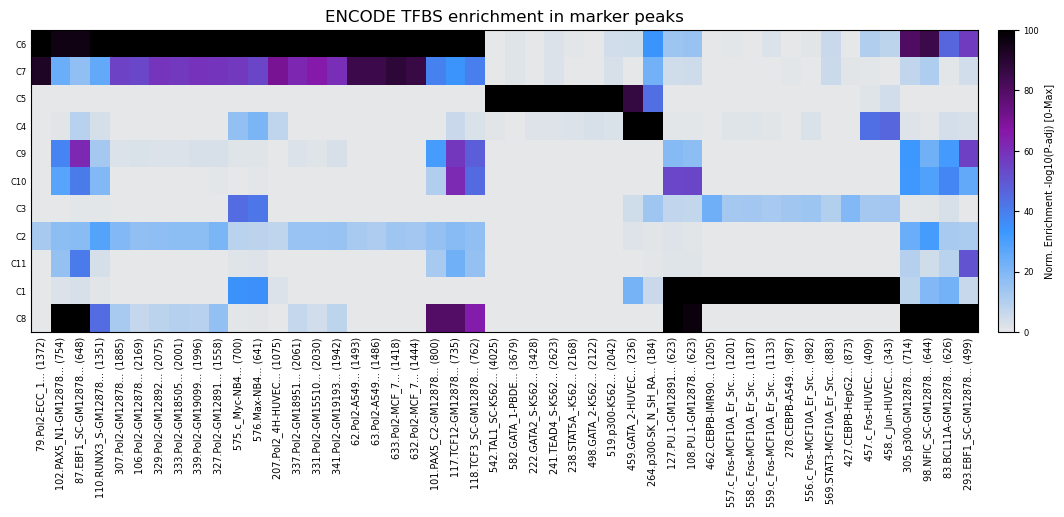

CPU times: user 16.8 s, sys: 1.26 s, total: 18.1 s
Wall time: 18.1 s


In [13]:
%%time
epi.tl.add_archr_annotations(adata, db='ArchR', collection='EncodeTFBS', genome='hg19',
                             cache_dir=str(ANNO_CACHE))
display(adata.uns['EncodeTFBS_info'].head(3))
enrich_encode = epi.tl.peak_anno_enrichment(markers, adata, annotation='EncodeTFBS', verbose=False)
fig, ax = epi.pl.enrich_heatmap(enrich_encode, n=7, transpose=True, figsize=(13, 4), show=False)
ax.set_title('ENCODE TFBS enrichment in marker peaks'); plt.show()

  └─ [add_archr_annotations] ATAC: 96/96 annotations overlap peaks


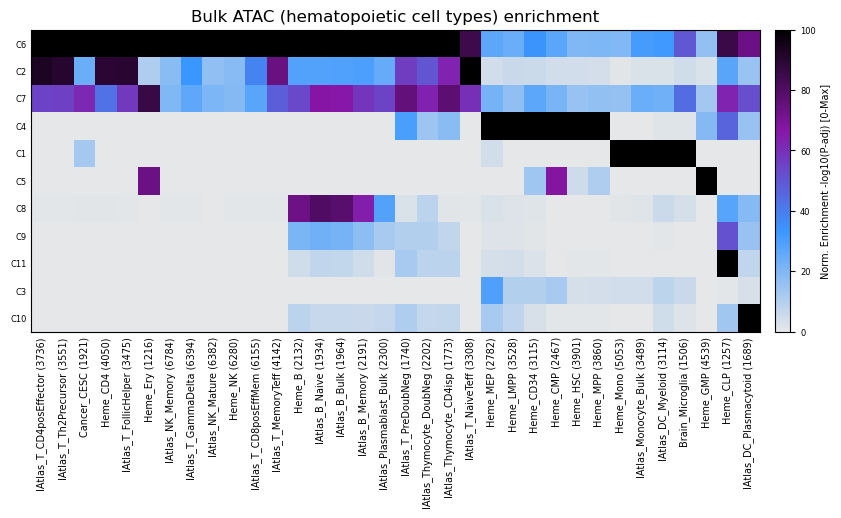

In [14]:
epi.tl.add_archr_annotations(adata, collection='ATAC', cache_dir=str(ANNO_CACHE))
enrich_atac = epi.tl.peak_anno_enrichment(markers, adata, annotation='ATAC', verbose=False)
fig, ax = epi.pl.enrich_heatmap(enrich_atac, n=5, transpose=True, figsize=(10, 4), show=False)
ax.set_title('Bulk ATAC (hematopoietic cell types) enrichment'); plt.show()

## Enrichment in an arbitrary peak set — `custom_enrichment`

`customEnrichment` tests any set of regions. Here: the 1,000 strongest marker peaks of
the erythroid cluster.

In [15]:
ery = markers[(markers['group'] == lineage['erythroid']) & (markers['fdr'] <= 0.1)] \
    .nlargest(1000, 'log2_fc')
ery_ranges = adata.var.loc[ery['feature'], ['chrom', 'start', 'end']]
epi.tl.custom_enrichment(ery_ranges, adata, annotation='motif').head(6)

,feature,CompareFrequency,nCompare,CompareProportion,BackgroundFrequency,nBackground,BackgroundProporition,Enrichment,mlog10p,mlog10Padj
MA0140.2_GATA1::TAL1,MA0140.2_GATA1::TAL1,472.0,1000.0,0.472,18012.0,232272.0,0.077547,6.086630,245.8926,244.938357
MA0482.2_GATA4,MA0482.2_GATA4,393.0,1000.0,0.393,20694.0,232272.0,0.089094,4.411080,148.8890,147.934757
MA0036.3_GATA2,MA0036.3_GATA2,371.0,1000.0,0.371,18498.0,232272.0,0.079639,4.658499,146.5454,145.591157
MA0037.3_GATA3,MA0037.3_GATA3,341.0,1000.0,0.341,17797.0,232272.0,0.076621,4.450455,126.9948,126.040557
MA1104.2_GATA6,MA1104.2_GATA6,348.0,1000.0,0.348,21755.0,232272.0,0.093662,3.715498,107.3023,106.348057
MA0766.2_GATA5,MA0766.2_GATA5,285.0,1000.0,0.285,14593.0,232272.0,0.062827,4.536252,105.3989,104.444657


## Parity vs ArchR

The enrichment stack was validated against ArchR 1.0.3 on ArchR's own Hematopoiesis
project (10,660 cells, 141,369 peaks, 11 clusters, JASPAR 2020 motif matches). To
test the enrichment layer deterministically, ArchR's own marker assays
(`getMarkerFeatures(PeakMatrix, groupBy = "Clusters", bias = c("TSSEnrichment", "log10(nFrags)"))`)
were fed to Epione and every output was compared element-wise. The ArchR reference
outputs are generated outside this repository; the gates were registered before the
first comparison in `tests/parity/peak_anno_enrichment/MANIFEST.md`, and
`tests/test_peak_anno_enrichment.py` re-checks them when `EPIONE_ARCHR_PARITY_DIR`
points at the reference outputs.

| Output | ArchR function | Class | Gate | Result |
|---|---|---|---|---|
| peak × annotation matrix, custom BED sets | `addPeakAnnotations` | 1 | 0 mismatches | 0, names identical |
| peak × annotation matrix, EncodeTFBS (× 689) / ATAC (× 96) | `addArchRAnnotations` | 1 | 0 mismatches | 0, names identical |
| 9 enrichment assays, motif, bg = all / bgdPeaks / OR cutoff | `peakAnnoEnrichment` | 1 | max abs err ≤ 1e-8 | 6.8e-13 / 3.4e-13 / 3.4e-13 |
| 9 enrichment assays, Region / EncodeTFBS / ATAC | `peakAnnoEnrichment` | 1 | ≤ 1e-8 | 2.8e-13 / 9.1e-13 / 9.1e-13 |
| unrounded −log10 p | `phyper(log.p = TRUE)` | 1 (bounded) | max rel err ≤ 1e-10 | 1.5e-13 |
| table + row order, all / bgd | `customEnrichment` | 1 | ≤ 1e-8, identical order | 3.4e-13, identical |
| heatmap matrix, 7 configurations | `plotEnrichHeatmap(returnMatrix = TRUE)` | 1 | ≤ 1e-8, identical dimnames | ≤ 6.4e-14, identical |
| hclust leaf order, 30 random inputs | `hclust(dist(x))$order` | 1 | 30/30 | 30/30 |
| end to end, Epione markers vs ArchR markers: Spearman(mlog10Padj) | full pipeline | 8 | ≥ 0.90 | **0.854 (fail)** |
| end to end: mean top-10 motifs Jaccard | full pipeline | 5 | ≥ 0.5 | 0.620 |

The one failed gate is upstream of this port. ArchR's `getMarkerFeatures`
depth-normalises each cell to 10⁴ (`scaleTo`), caps each group at `maxCells = 500`,
and computes `Log2FC` on the normalised means with a pseudocount of 1. Epione's
`find_marker_features` uses raw counts, up to 2000 cells per group, a pseudocount of
1e-6 and its own bias-matched background, so the same `FDR <= 0.1 & Log2FC >= 0.5`
cutoff selects 1.4–4.3× more marker peaks per cluster. Given identical marker
statistics, the enrichment layer is exact (rows above).